# Wang et al. 2019 — Glioblastoma (10x) · 02 Manifold
**Biology before geometry, on the NATIVE integrated embedding (no re-embedding).** Score the three embryonic
modules, then interrogate the module geography honestly: raw per-cell scores on the native `X_umap`, a null test
that isolates how much of any apparent Gast/pSom/Crest structure is real vs. an artifact of the shared `union`
control pool, and each lobe's biology + cell cycle. A curve is fit on the native embedding for completeness, but the
gate call (03) is made on the module geography shown here, not on any pseudotime metric.

In [1]:
import os, sys, glob, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold (native embedding):', adata.shape[0], 'cells')
# score modules with the union control pool (deliverable convention)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
real = {}
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]; real[lab] = g.tolist()
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth (union-pool scores) for reading geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold (native embedding): 9634 cells
Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 100/104 genes present


### Raw module geography on the NATIVE embedding
The reference GO pattern (e.g. Neftel 2019 GBM) is legible in the *raw* per-cell scores. Here the raw Gast / pSom /
Crest scores are salt-and-pepper — no hub, no arms, no coherent gradient.

RAW per-cell module correlations (union pool):
  Gast-pSom -0.080 | Crest-Gast -0.414 | Crest-pSom -0.607
  Gast: spatial-structure ratio var(local-mean)/var(raw) = 0.119
  pSom: spatial-structure ratio var(local-mean)/var(raw) = 0.129
  Crest: spatial-structure ratio var(local-mean)/var(raw) = 0.152
reference GBM GO (Neftel) has ratios 0.23-0.39 and raw Gast-pSom = +0.37; here ratios ~0.12-0.15 -> ~85% noise.


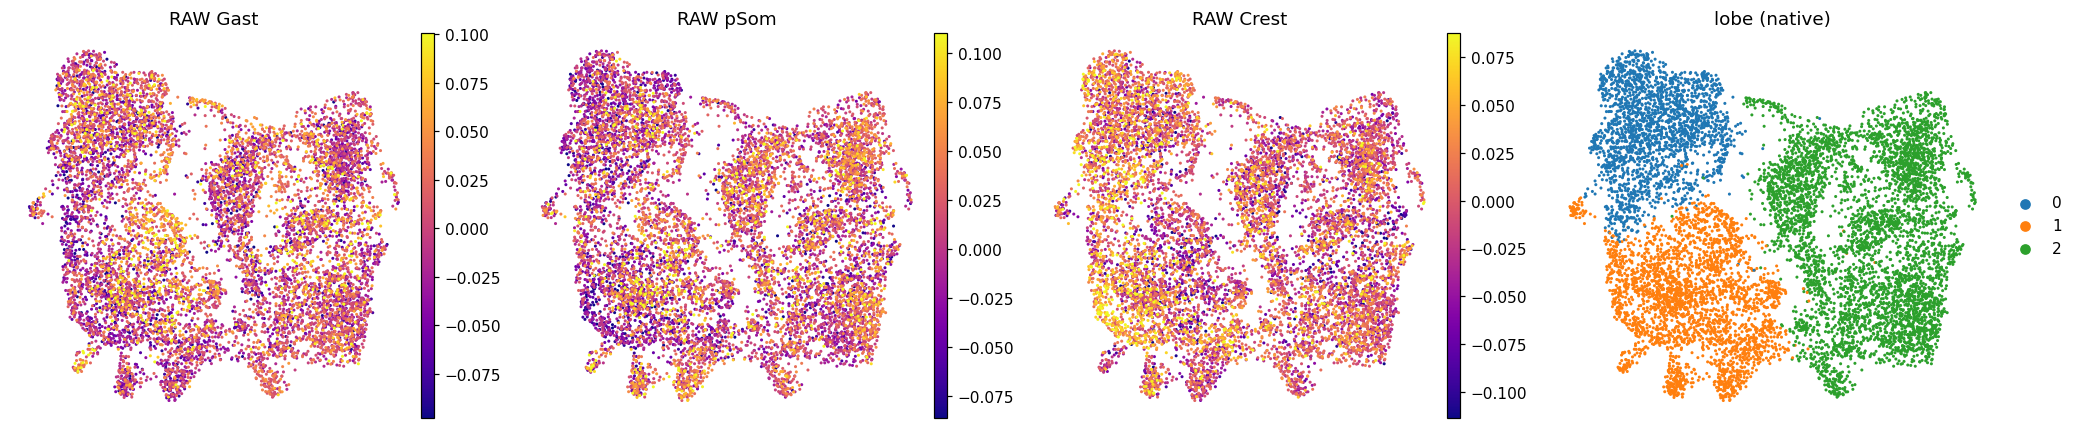

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, col in zip(axes, ['Gast','pSom','Crest']):
    v = adata.obs[col].values; lo, hi = np.percentile(v, [2, 98])
    sc.pl.umap(adata, color=col, size=16, frameon=False, show=False, ax=ax, cmap='plasma', title='RAW '+col, vmin=lo, vmax=hi)
sc.pl.umap(adata, color='lobe', size=16, frameon=False, show=False, ax=axes[3], title='lobe (native)')
fig.tight_layout(); plt.show()
raw = adata.obs[['Gast','pSom','Crest']].values
print('RAW per-cell module correlations (union pool):')
print('  Gast-pSom %+.3f | Crest-Gast %+.3f | Crest-pSom %+.3f' % (
    np.corrcoef(raw[:,0],raw[:,1])[0,1], np.corrcoef(raw[:,2],raw[:,0])[0,1], np.corrcoef(raw[:,2],raw[:,1])[0,1]))
# spatial-structure ratio: how much of each score's variance survives kNN-averaging (0=noise, ->1=smooth gradient)
for m in ['Gast','pSom','Crest']:
    v = adata.obs[m].values.astype(float); lv = np.asarray(A @ v).ravel()
    print(f'  {m}: spatial-structure ratio var(local-mean)/var(raw) = {lv.var()/v.var():.3f}')
print('reference GBM GO (Neftel) has ratios 0.23-0.39 and raw Gast-pSom = +0.37; here ratios ~0.12-0.15 -> ~85% noise.')

### Null test — is the module structure real, or an artifact of the shared union control pool?
`score_genes` subtracts a control drawn from `gene_pool`. Because pSom and Crest genes are BOTH subsets of the
union pool, each is scored against a control containing the other's genes — which mechanically induces a negative
correlation. We re-score with a neutral (full-transcriptome) control and compare against 30 random size-matched
gene-set pairs.

In [5]:
for m in real: sc.tl.score_genes(adata, gene_list=real[m], score_name=m+'_d', random_state=1234)  # neutral control
def smooth(v):
    x = v.astype(float).copy()
    for _ in range(3): x = np.asarray(A @ x).ravel()
    return x
obs_raw_pc = np.corrcoef(adata.obs['pSom_d'], adata.obs['Crest_d'])[0,1]
obs_raw_gp = np.corrcoef(adata.obs['Gast_d'], adata.obs['pSom_d'])[0,1]
obs_raw_cg = np.corrcoef(adata.obs['Crest_d'], adata.obs['Gast_d'])[0,1]
pool = np.array(adata.var_names); rng = np.random.default_rng(0); nr = []
for k in range(30):
    rp = list(rng.choice(pool, size=len(real['pSom']), replace=False))
    rc = list(rng.choice(pool, size=len(real['Crest']), replace=False))
    sc.tl.score_genes(adata, gene_list=rp, score_name='_p', random_state=1)
    sc.tl.score_genes(adata, gene_list=rc, score_name='_c', random_state=1)
    nr.append(np.corrcoef(adata.obs['_p'], adata.obs['_c'])[0,1])
nr = np.array(nr)
print('NEUTRAL control (removes the pool artifact):')
print(f'  Gast-pSom {obs_raw_gp:+.3f} | Crest-Gast {obs_raw_cg:+.3f} | Crest-pSom {obs_raw_pc:+.3f}')
print(f'  null pSom-Crest r: mean {nr.mean():+.3f} sd {nr.std():.3f}  -> observed z = {(obs_raw_pc-nr.mean())/nr.std():+.2f}')
print('All three modules correlate POSITIVELY under a neutral control: one degenerate "all-embryonic-together"')
print('signal with NO Crest opposition. The union-pool -0.61 pSom-Crest was the artifact, amplified by smoothing.')
del adata.obs['_p'], adata.obs['_c']

NEUTRAL control (removes the pool artifact):
  Gast-pSom +0.618 | Crest-Gast +0.465 | Crest-pSom +0.374
  null pSom-Crest r: mean +0.020 sd 0.093  -> observed z = +3.81
All three modules correlate POSITIVELY under a neutral control: one degenerate "all-embryonic-together"
signal with NO Crest opposition. The union-pool -0.61 pSom-Crest was the artifact, amplified by smoothing.


### Lobe biology + cell cycle (settle scope before any trajectory)
Cell cycle is orthogonal to the modules and uniform across lobes (a scattered minority, not a cycling lobe), so
there is no cycling compartment to scope away. But the raw modules are near-flat across all three lobes — so there
is also no embryonic lobe to scope *to*.

In [6]:
g = adata.obs.groupby('lobe', observed=True)[['Gast','pSom','Crest']].mean()
sd = adata.obs[['Gast','pSom','Crest']].std()
print('per-lobe RAW module means:'); print(g.round(4).to_string())
print('in SD units (lobe-mean / per-cell SD):'); print((g/sd).round(2).to_string())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(2).to_dict())
print('cyc_score vs modules (whole manifold):', {m: round(float(np.corrcoef(adata.obs.cyc_score, adata.obs[m])[0,1]),2) for m in ['Gast_sm','pSom_sm','Crest_sm']})
# does ANY lobe reproduce the reference relationships (Gast/pSom co-vary AND both oppose Crest) under neutral control?
print('\nper-lobe reference-relationship test (neutral control): need Gast-pSom>0, Crest-Gast<0, Crest-pSom<0')
for lb in sorted(adata.obs['lobe'].unique(), key=int):
    m = (adata.obs['lobe']==lb).values
    gp = np.corrcoef(adata.obs['Gast_d'][m], adata.obs['pSom_d'][m])[0,1]
    cg = np.corrcoef(adata.obs['Crest_d'][m], adata.obs['Gast_d'][m])[0,1]
    cp = np.corrcoef(adata.obs['Crest_d'][m], adata.obs['pSom_d'][m])[0,1]
    ok = (gp>0) and (cg<0) and (cp<0)
    print(f'  lobe {lb} (n={m.sum()}): Gast-pSom {gp:+.3f} | Crest-Gast {cg:+.3f} | Crest-pSom {cp:+.3f} -> {"YES" if ok else "NO"}')
print('-> no lobe reproduces the reference geometry; nothing to scope to. (Gate 2 verdict is made in 03.)')

per-lobe RAW module means:
        Gast    pSom   Crest
lobe                        
0    -0.0040 -0.0022  0.0018
1    -0.0027  0.0052 -0.0057
2    -0.0016  0.0138 -0.0126
in SD units (lobe-mean / per-cell SD):
      Gast  pSom  Crest
lobe                   
0    -0.08 -0.05   0.04
1    -0.06  0.11  -0.12
2    -0.03  0.29  -0.27
cycling fraction per lobe: {'0': 0.23, '1': 0.31, '2': 0.23}
cyc_score vs modules (whole manifold): {'Gast_sm': -0.06, 'pSom_sm': 0.09, 'Crest_sm': -0.1}

per-lobe reference-relationship test (neutral control): need Gast-pSom>0, Crest-Gast<0, Crest-pSom<0
  lobe 0 (n=2150): Gast-pSom +0.603 | Crest-Gast +0.433 | Crest-pSom +0.385 -> NO
  lobe 1 (n=2854): Gast-pSom +0.707 | Crest-Gast +0.536 | Crest-pSom +0.464 -> NO
  lobe 2 (n=4630): Gast-pSom +0.525 | Crest-Gast +0.410 | Crest-pSom +0.281 -> NO
-> no lobe reproduces the reference geometry; nothing to scope to. (Gate 2 verdict is made in 03.)


### Fit a curve on the NATIVE embedding (for completeness)
A principal curve can be fit to any cloud; it is fold-free here, but note (above) the modules do NOT vary coherently
along it with the reference relationships. The gate is decided on module geography (03), not on this fit.

In [7]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    dmin = np.inf
    for i in range(F.shape[0]):
        for j in range(i+1, F.shape[0]):
            if G[i,j] >= 3: dmin = min(dmin, np.sqrt(((F[i]-F[j])**2).sum()))
    ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve on native X_umap: {tips} tips, {forks} forks, fold self-approach {sa:.2f}')
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1); D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {tp:(adata.obs['Gast_sm'][np.isin(hard,np.where(D[tp]<=3)[0])].mean(),
            adata.obs['pSom_sm'][np.isin(hard,np.where(D[tp]<=3)[0])].mean(),
            adata.obs['Crest_sm'][np.isin(hard,np.where(D[tp]<=3)[0])].mean()) for tp in tps}
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
print('curve root tip', root, '| pseudotime range %.2f-%.2f' % (adata.obs['t'].min(), adata.obs['t'].max()))

curve on native X_umap: 2 tips, 0 forks, fold self-approach 2.83
curve root tip 2 | pseudotime range 0.00-12.41


### Figure — manifold.pdf (native embedding, curve edges overlaid, pseudotime)

saved manifold.h5ad + manifold.pdf (native embedding)


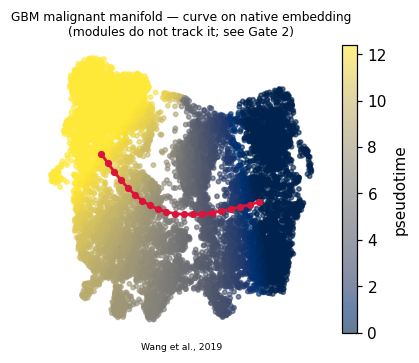

In [8]:
F = np.asarray(adata.uns['graph']['F']); Bc = np.asarray(adata.uns['graph']['B']); ii, jj = np.where(np.triu(Bc>0))
t = adata.obs['t'].values
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}  # sanitize non-serializable ElPiGraph entry
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
fig, ax = plt.subplots(figsize=(4.2, 3.4))
sca = ax.scatter(adata.obsm['X_umap'][:,0], adata.obsm['X_umap'][:,1], c=t, cmap='cividis', s=8, alpha=.6)
for a, b in zip(ii, jj):
    ax.plot([F[0,a],F[0,b]], [F[1,a],F[1,b]], '-', color='crimson', lw=1.8, zorder=5)
ax.scatter(F[0], F[1], c='crimson', s=14, zorder=6)
ax.axis('off'); ax.set_title('GBM malignant manifold — curve on native embedding\n(modules do not track it; see Gate 2)', size=8)
plt.colorbar(sca, ax=ax, label='pseudotime')
ax.text(.5, -.06, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf (native embedding)')